In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

## Tấn Hiệp – Demo 5: Xoay ảnh (warping ngược, nội suy)



In [2]:
def tao_ban_co(kich_thuoc=200, o=25, sang=220, toi=60):
    ban_co = np.zeros((kich_thuoc, kich_thuoc), dtype=np.uint8)
    for y in range(kich_thuoc):
        for x in range(kich_thuoc):
            if (x // o + y // o) % 2 == 0:
                ban_co[y, x] = sang
            else:
                ban_co[y, x] = toi
    return ban_co


def ma_tran_xoay(goc_do, cx, cy):
    t = np.deg2rad(goc_do)
    c, s = np.cos(t), np.sin(t)

    T_ve_goc = np.array([[1, 0, -cx],
                         [0, 1, -cy],
                         [0, 0, 1]])
    R = np.array([[c, s, 0],
                  [-s, c, 0],
                  [0, 0, 1]])
    T_ve_tam = np.array([[1, 0, cx],
                         [0, 1, cy],
                         [0, 0, 1]])

    return T_ve_tam @ R @ T_ve_goc


ban_co = tao_ban_co()
h, w = ban_co.shape
cx, cy = (w - 1) / 2, (h - 1) / 2

M = ma_tran_xoay(30, cx, cy)
tam_sau_xoay = M @ np.array([cx, cy, 1])
print("Ma trận xoay 30 độ:\n", np.round(M, 3))
print(f"Tâm trước khi xoay: ({cx:.2f}, {cy:.2f})")
print(f"Tâm sau khi xoay:  ({tam_sau_xoay[0]:.2f}, {tam_sau_xoay[1]:.2f})")
print("Tâm không đổi:", "Có" if np.allclose(tam_sau_xoay[:2], [cx, cy]) else "Không")

Ma trận xoay 30 độ:
 [[  0.866   0.5   -36.42 ]
 [ -0.5     0.866  63.08 ]
 [  0.      0.      1.   ]]
Tâm trước khi xoay: (99.50, 99.50)
Tâm sau khi xoay:  (99.50, 99.50)
Tâm không đổi: Có


In [3]:
def lay_gan_nhat(anh, x, y):
    h, w = anh.shape
    xi = int(np.round(x))
    yi = int(np.round(y))
    if xi < 0 or xi >= w or yi < 0 or yi >= h:
        return 0.0
    return float(anh[yi, xi])


def lay_song_tuyen(anh, x, y):
    h, w = anh.shape
    eps = 1e-6
    if x < -eps or x > w - 1 + eps or y < -eps or y > h - 1 + eps:
        return 0.0

    x = min(max(x, 0.0), w - 1)
    y = min(max(y, 0.0), h - 1)

    x0 = int(np.floor(x))
    y0 = int(np.floor(y))
    x1 = min(x0 + 1, w - 1)
    y1 = min(y0 + 1, h - 1)

    dx = x - x0
    dy = y - y0

    Q11 = float(anh[y0, x0])
    Q21 = float(anh[y0, x1])
    Q12 = float(anh[y1, x0])
    Q22 = float(anh[y1, x1])

    R1 = (1 - dx) * Q11 + dx * Q21
    R2 = (1 - dx) * Q12 + dx * Q22
    P = (1 - dy) * R1 + dy * R2
    return P


def xoay_anh(anh, goc_do, kieu="song_tuyen"):
    if kieu == "gan_nhat":
        lay_mau = lay_gan_nhat
    elif kieu == "song_tuyen":
        lay_mau = lay_song_tuyen
    else:
        raise ValueError("kieu phải là 'gan_nhat' hoặc 'song_tuyen'")

    h, w = anh.shape
    M = ma_tran_xoay(goc_do, (w - 1) / 2, (h - 1) / 2)
    M_nguoc = np.linalg.inv(M)

    ket_qua = np.zeros((h, w), dtype=np.float64)
    for y_dich in range(h):
        for x_dich in range(w):
            x_nguon, y_nguon, _ = M_nguoc @ np.array([x_dich, y_dich, 1.0])
            ket_qua[y_dich, x_dich] = lay_mau(anh, x_nguon, y_nguon)

    return np.clip(np.round(ket_qua), 0, 255).astype(np.uint8)

In [4]:
goc = 30
anh_gan_nhat = xoay_anh(ban_co, goc, "gan_nhat")
anh_song_tuyen = xoay_anh(ban_co, goc, "song_tuyen")

anh_list = [ban_co, anh_gan_nhat, anh_song_tuyen]
ten_list = ["Bàn cờ gốc", f"Xoay {goc} độ – nội suy gần nhất", f"Xoay {goc} độ – nội suy song tuyến"]

y1, y2, x1, x2 = 40, 80, 100, 140

plt.figure(figsize=(13, 4.5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(anh_list[i], cmap="gray", vmin=0, vmax=255)
    plt.plot(cx, cy, "r+", markersize=12)
    if i > 0:
        plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                          fill=False, edgecolor="yellow", linewidth=1.5))
    plt.title(ten_list[i], fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
for i in range(1, 3):
    plt.subplot(1, 2, i)
    plt.imshow(anh_list[i][y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255,
               interpolation="nearest")
    plt.title(ten_list[i] + " (phóng to)", fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Ô đối chiếu thư viện (chỉ ở đây mới gọi `cv2.getRotationMatrix2D`, `cv2.warpAffine`)

### Có dùng AI hỗ trợ

Công cụ: Codex (OpenAI)

Mục đích: Viết code so sánh kết quả xoay ảnh với OpenCV.

Prompt:
> Viết giúp tôi ô so sánh ma trận xoay và hai ảnh xoay gần nhất, song tuyến của tôi với OpenCV. In ra ma trận có khớp không và sai lệch trung bình của hai ảnh. Giữ nguyên các hàm tôi đã viết.

Đã sửa lại những gì: Chưa chỉnh sửa thêm.

In [5]:
M_cv = cv2.getRotationMatrix2D((cx, cy), goc, 1.0)
cv_gan_nhat = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_NEAREST)
cv_song_tuyen = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_LINEAR)

print("Ma trận tự xây trùng với OpenCV:", "Có" if np.allclose(ma_tran_xoay(goc, cx, cy)[:2], M_cv) else "Không")
print("Gần nhất   - sai lệch trung bình so với OpenCV:",
      round(np.mean(np.abs(anh_gan_nhat.astype(int) - cv_gan_nhat)), 4))
print("Song tuyến - sai lệch trung bình so với OpenCV:",
      round(np.mean(np.abs(anh_song_tuyen.astype(int) - cv_song_tuyen)), 4))

Ma trận tự xây trùng với OpenCV: Có
Gần nhất   - sai lệch trung bình so với OpenCV: 0.0
Song tuyến - sai lệch trung bình so với OpenCV: 0.6021


### Có dùng AI hỗ trợ

Công cụ: Codex (OpenAI)

Mục đích: Viết code kiểm tra kết quả ở các góc xoay đặc biệt.

Prompt:
> Dùng hàm xoay_anh có sẵn để thử các góc 0, 90, 180, 270 và 360 độ với cả gần nhất và song tuyến. Đếm pixel đen trên ảnh sáng đều và so ảnh bàn cờ sau xoay với np.rot90. In kết quả từng trường hợp giúp tôi.

Đã sửa lại những gì: Chưa chỉnh sửa thêm.

In [6]:
anh_sang = np.full((200, 200), 200, dtype=np.uint8)

ten_kieu = {"gan_nhat": "gần nhất", "song_tuyen": "song tuyến"}

for goc_thu, k in [(0, 0), (90, 1), (180, 2), (270, 3), (360, 0)]:
    for kieu in ["gan_nhat", "song_tuyen"]:
        kq_sang = xoay_anh(anh_sang, goc_thu, kieu)
        kq_ban_co = xoay_anh(ban_co, goc_thu, kieu)
        so_den = int(np.sum(kq_sang == 0))
        dung_rot90 = np.array_equal(kq_ban_co, np.rot90(ban_co, k))
        ket_luan = "Có" if dung_rot90 else "Không"
        print(f"{goc_thu:3d} độ {ten_kieu[kieu]:10s}: {so_den} pixel đen, "
              f"trùng với np.rot90 (k={k}): {ket_luan}")

  0 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=0): Có


  0 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=0): Có


 90 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=1): Có


 90 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=1): Có


180 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=2): Có


180 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=2): Có


270 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=3): Có


270 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=3): Có


360 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=0): Có


360 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=0): Có


In [7]:
plt.imsave("../images/xoay_gan_nhat.png", anh_gan_nhat, cmap="gray", vmin=0, vmax=255)
plt.imsave("../images/xoay_song_tuyen.png", anh_song_tuyen, cmap="gray", vmin=0, vmax=255)
print("Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png")

Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png


## KT3 – Hough đa tỉ lệ


Nạp các hàm dùng chung từ notebook của Lên và Gấm. Chỉ lấy định nghĩa hàm, không chạy các ô demo hay ghi ảnh của hai notebook.

In [8]:
import ast
import json
from pathlib import Path

thu_muc = Path.cwd()
if not (thu_muc / "len.ipynb").is_file():
    thu_muc = thu_muc / "lam_viec"

ham_dung_chung = {
    "len.ipynb": {"convolve2d", "smooth_accumulator", "hough_accumulate", "find_peaks"},
    "gam.ipynb": {"angle_error", "rho_error"}
}

for ten_file, cac_ten_ham in ham_dung_chung.items():
    with open(thu_muc / ten_file, encoding="utf-8") as file:
        noi_dung = json.load(file)
    da_nap = set()
    for o in noi_dung["cells"]:
        if o["cell_type"] != "code":
            continue
        cay = ast.parse("".join(o["source"]))
        for ham in cay.body:
            if isinstance(ham, ast.FunctionDef) and ham.name in cac_ten_ham:
                ma = ast.Module(body=[ham], type_ignores=[])
                exec(compile(ma, str(thu_muc / ten_file), "exec"), globals())
                da_nap.add(ham.name)
    if da_nap != cac_ten_ham:
        raise NameError(f"Thiếu hàm trong {ten_file}: {cac_ten_ham - da_nap}")


In [9]:
def hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8,
                     n_peaks=10, rho_step=2.0, theta_step_deg=1.0,
                     delta_deg=10.0):


    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")
    if int(n_levels) != n_levels or n_levels < 0:
        raise ValueError("n_levels phải là số nguyên không âm")
    if int(refine_factor) != refine_factor or refine_factor <= 1:
        raise ValueError("refine_factor phải là số nguyên lớn hơn 1")
    if rho_step <= 0 or not 0 < theta_step_deg < 180:
        raise ValueError("Bước rho và theta không hợp lệ")
    n_levels = int(n_levels)
    refine_factor = int(refine_factor)
    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir)

    h, w = edges.shape
    ys, xs = np.nonzero(edges)
    if len(xs) == 0:
        return []

    D = np.ceil(np.sqrt(h*h + w*w) / rho_step) * rho_step
    n_rho = int(round(2 * D / rho_step)) + 1
    n_theta = int(np.ceil(180 / theta_step_deg))
    A, thetas, rhos = hough_accumulate(
        edges, (0, np.pi), (-D, D), n_theta, n_rho,
        grad_dir=grad_dir, delta_deg=delta_deg)
    peaks = find_peaks(A, n_peaks, thetas=thetas, rhos=rhos)
    ket_qua = []

    for rho, theta, _ in peaks:
        rho_diem = xs * np.cos(theta) + ys * np.sin(theta)
        chi_so = np.rint((rho_diem + D) / rho_step).astype(int)
        o_rho = int(round((rho + D) / rho_step))
        chon = chi_so == o_rho
        if grad_dir is not None:
            g = np.asarray(grad_dir)[ys, xs]
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            chon &= lech <= np.deg2rad(delta_deg)
        if not np.any(chon):
            continue

        canh_chon = np.zeros_like(edges, dtype=bool)
        canh_chon[ys[chon], xs[chon]] = True
        dr, dt = rho_step, np.pi / n_theta

        for _ in range(n_levels):
            rho_range = (rho - dr, rho + dr)
            theta_range = (theta - dt, theta + dt + dt / refine_factor)
            A_moi, t_moi, r_moi = hough_accumulate(
                canh_chon, theta_range, rho_range,
                2 * refine_factor + 1, 2 * refine_factor + 1,
                grad_dir=grad_dir, delta_deg=delta_deg)
            dinh_moi = find_peaks(A_moi, 1, thetas=t_moi, rhos=r_moi)
            if not dinh_moi:
                break
            rho, theta, _ = dinh_moi[0]
            dr /= refine_factor
            dt /= refine_factor


        while theta < 0:
            theta += np.pi
            rho = -rho
        while theta >= np.pi:
            theta -= np.pi
            rho = -rho

        ket_qua.append((float(rho), float(theta)))

    return ket_qua


## Kiểm thử hai góc 0.5 độ và 179.5 độ

Dùng ảnh và hàm đo sai số của Gấm. Ô kiểm thử chỉ chạy các hàm của nhóm: Hough đa tỉ lệ và Hough thô bước 1 độ (`n_levels=0`). Kiểm tra khoảng góc, dấu rho và sai số góc; báo cả trường hợp chưa đạt. Ô đối chiếu thư viện riêng bên dưới gọi OpenCV, lập bảng so sánh và vẽ kết quả.


### Có dùng AI hỗ trợ
Công cụ: Codex

Mục đích: Dựng thí nghiệm kiểm thử hai góc 0.5 độ và 179.5 độ; so sánh với Hough thô bước 1 độ, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và đường phát hiện.

Prompt:
> sử dụng các hàm có sẵn để kiểm thử ảnh chứa đường ở góc 0.5 và 179.5, đối chiếu với Hough thô bước 1, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và kết quả phát hiện, không thay đổi các hàm cài đặt, nêu rõ dữ liệu và tham số thí nghiệm đã dùng, báo cả trường hợp không đạt và chỉ sử dụng thư viện được đề cho phép.



In [10]:
thu_muc_anh = thu_muc.parent / "images"
cac_ca = [("hough_angle_0_5.png", 200.0, 0.5),
          ("hough_angle_179_5.png", -200.0, 179.5)]
ket_qua_nhom = []
sai_so_moi, sai_so_n0 = [], []
tat_ca_dat_nhom = True

print("Dữ liệu: ảnh của Gấm trong thư mục images; giá trị chuẩn (rho, θ):")
for ten_anh, rho0, theta0 in cac_ca:
    print(f"  {ten_anh}: rho = {rho0:g} pixel, θ = {theta0} độ")
print("Tham số nhóm: n_levels=2, refine_factor=8; Hough thô: n_levels=0 (bước 1 độ).")
print("Góc chuẩn | Góc tìm được | Sai số góc | Sai số rho | Sai số góc Hough thô nhóm | Kết quả")
for ten_anh, rho0, theta0 in cac_ca:
    anh = cv2.imread(str(thu_muc_anh / ten_anh), cv2.IMREAD_GRAYSCALE)
    if anh is None:
        raise FileNotFoundError(f"Không đọc được {ten_anh}")
    cac_duong = hough_multiscale(anh > 0, None, n_levels=2, refine_factor=8)
    cac_duong_n0 = hough_multiscale(anh > 0, None, n_levels=0)
    if not cac_duong or not cac_duong_n0:
        print(f"{theta0:9.2f} độ | CHƯA ĐẠT: hàm nhóm không tìm thấy đường")
        tat_ca_dat_nhom = False
        ket_qua_nhom.append((anh, rho0, theta0, None, None, None, None, None))
        continue
    rho, theta = cac_duong[0]
    ss_goc = angle_error(theta0, np.rad2deg(theta))
    ss_rho = rho_error(rho0, theta0, rho, np.rad2deg(theta))
    rho_n0, theta_n0 = cac_duong_n0[0]
    ss_n0 = angle_error(theta0, np.rad2deg(theta_n0))
    dat = 0 <= theta < np.pi and rho * rho0 > 0 and ss_goc < ss_n0
    tat_ca_dat_nhom = tat_ca_dat_nhom and dat
    sai_so_moi.append(ss_goc)
    sai_so_n0.append(ss_n0)
    ket_qua_nhom.append((anh, rho0, theta0, rho, theta, ss_goc, ss_rho, ss_n0))
    print(f"{theta0:9.2f} độ | {np.rad2deg(theta):11.3f} độ | {ss_goc:9.3f} độ | "
          f"{ss_rho:8.3f} | {ss_n0:25.3f} độ | {'ĐẠT' if dat else 'CHƯA ĐẠT'}")

print("Kiểm thử nhóm:", "ĐẠT" if tat_ca_dat_nhom else "CHƯA ĐẠT")


Dữ liệu: ảnh của Gấm trong thư mục images; giá trị chuẩn (rho, θ):
  hough_angle_0_5.png: rho = 200 pixel, θ = 0.5 độ
  hough_angle_179_5.png: rho = -200 pixel, θ = 179.5 độ
Tham số nhóm: n_levels=2, refine_factor=8; Hough thô: n_levels=0 (bước 1 độ).
Góc chuẩn | Góc tìm được | Sai số góc | Sai số rho | Sai số góc Hough thô nhóm | Kết quả


     0.50 độ |       0.422 độ |     0.078 độ |    0.500 |                     0.500 độ | ĐẠT


   179.50 độ |     179.562 độ |     0.062 độ |    0.406 |                     0.500 độ | ĐẠT
Kiểm thử nhóm: ĐẠT


### Ô đối chiếu thư viện

Chỉ ô mã bên dưới gọi `cv2.HoughLines` để đối chiếu với kết quả của nhóm; không dùng hàm này trong phần cài đặt. Tham số OpenCV: bước rho = 1 pixel, bước θ = 1 độ, ngưỡng phiếu = 50.


### Có dùng AI hỗ trợ
Công cụ: Codex

Mục đích: Dựng thí nghiệm kiểm thử hai góc 0.5 độ và 179.5 độ; so sánh với Hough thô bước 1 độ, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và đường phát hiện.

Prompt:
> sử dụng các hàm có sẵn để kiểm thử ảnh chứa đường ở góc 0.5 và 179.5, đối chiếu với Hough thô bước 1, lập bảng sai số góc và rho, vẽ ảnh cùng đường chuẩn và kết quả phát hiện, không thay đổi các hàm cài đặt, nêu rõ dữ liệu và tham số thí nghiệm đã dùng, báo cả trường hợp không đạt và chỉ sử dụng thư viện được đề cho phép.



In [11]:
ket_qua_thu = []
sai_so_tho = []
tat_ca_dat = tat_ca_dat_nhom
print("Đối chiếu OpenCV: bước rho = 1 pixel, bước θ = 1 độ, ngưỡng phiếu = 50.")
print("Góc chuẩn | Sai số góc nhóm | Sai số rho nhóm | Sai số góc OpenCV | Sai số rho OpenCV | Kết quả")
for anh, rho0, theta0, rho, theta, ss_goc, ss_rho, ss_n0 in ket_qua_nhom:
    duong_tho = cv2.HoughLines(anh, 1, np.pi / 180, 50)
    if duong_tho is None:
        print(f"{theta0:9.2f} độ | CHƯA ĐẠT: OpenCV không tìm thấy đường")
        tat_ca_dat = False
        continue
    rho_tho, theta_tho = duong_tho[0, 0]
    ss_tho = angle_error(theta0, np.rad2deg(theta_tho))
    ss_rho_tho = rho_error(rho0, theta0, rho_tho, np.rad2deg(theta_tho))
    if rho is None:
        print(f"{theta0:9.2f} độ | CHƯA ĐẠT: hàm nhóm không tìm thấy đường; "
              f"OpenCV: sai số góc {ss_tho:.3f} độ, sai số rho {ss_rho_tho:.3f} pixel")
        tat_ca_dat = False
        continue
    dat = 0 <= theta < np.pi and rho * rho0 > 0 and ss_goc < ss_n0 and ss_goc < ss_tho
    tat_ca_dat = tat_ca_dat and dat
    sai_so_tho.append(ss_tho)
    ket_qua_thu.append((anh, rho0, theta0, rho, theta, rho_tho, theta_tho))
    print(f"{theta0:9.2f} độ | {ss_goc:15.3f} độ | {ss_rho:13.3f} | "
          f"{ss_tho:17.3f} độ | {ss_rho_tho:15.3f} | {'ĐẠT' if dat else 'CHƯA ĐẠT'}")

if len(ket_qua_thu) == len(cac_ca):
    tb_moi = np.mean(sai_so_moi)
    tb_n0 = np.mean(sai_so_n0)
    tb_tho = np.mean(sai_so_tho)
    print(f"\nSai số góc trung bình: Hough đa tỉ lệ {tb_moi:.3f} độ")
    print(f"Hough thô của nhóm: {tb_n0:.3f} độ; Hough thô OpenCV: {tb_tho:.3f} độ")
else:
    print("Không tính trung bình toàn bộ: có trường hợp không tìm thấy đường.")
print("Đối chiếu toàn bộ:", "ĐẠT" if tat_ca_dat else "CHƯA ĐẠT")

if ket_qua_thu:
    fig, axes = plt.subplots(2, len(ket_qua_thu), figsize=(5.5 * len(ket_qua_thu), 9), squeeze=False)
    for cot, (anh, rho0, theta0, rho, theta, rho_tho, theta_tho) in enumerate(ket_qua_thu):
        h, w = anh.shape
        ys, xs = np.nonzero(anh)
        y_cuoi = ys.max()
        x_cuoi = xs[ys == y_cuoi].mean()
        y = np.arange(h)
        cac_duong_ve = [(rho0, np.deg2rad(theta0), "lime", "--", "Đường chuẩn"),
                         (rho, theta, "red", "-", "Hough đa tỉ lệ"),
                         (rho_tho, theta_tho, "deepskyblue", ":", "Hough thô (bước 1 độ)")]
        for hang in range(2):
            ax = axes[hang, cot]
            ax.imshow(anh, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
            for r, t, mau, kieu, nhan in cac_duong_ve:
                x = (r - y * np.sin(t)) / np.cos(t)
                ax.plot(x, y, linestyle=kieu, color=mau, linewidth=1, label=nhan)
            if hang == 0:
                ax.set_xlim(-0.5, w - 0.5)
                ax.set_ylim(h - 0.5, -0.5)
                ax.set_title(f"Ảnh thử của Gấm: θ = {theta0} độ, rho = {rho0:g}")
            else:
                ax.set_xlim(x_cuoi - 5, x_cuoi + 5)
                ax.set_ylim(y_cuoi + 5, y_cuoi - 25)
                ax.set_title("Phóng to đầu dưới đoạn thẳng")
            ax.set_xlabel("Cột x (pixel)")
            ax.set_ylabel("Hàng y (pixel)")
    axes[0, 0].legend(loc="lower left")
    plt.tight_layout()
    plt.show()


Đối chiếu OpenCV: bước rho = 1 pixel, bước θ = 1 độ, ngưỡng phiếu = 50.
Góc chuẩn | Sai số góc nhóm | Sai số rho nhóm | Sai số góc OpenCV | Sai số rho OpenCV | Kết quả
     0.50 độ |           0.078 độ |         0.500 |             0.500 độ |           2.000 | ĐẠT
   179.50 độ |           0.062 độ |         0.406 |             0.500 độ |           2.000 | ĐẠT

Sai số góc trung bình: Hough đa tỉ lệ 0.070 độ
Hough thô của nhóm: 0.500 độ; Hough thô OpenCV: 0.500 độ
Đối chiếu toàn bộ: ĐẠT


## KT2 (c) – Đo thời gian 3 cách tính trung bình cục bộ

Theo Computer_Vision_40.pdf mục 3.4 và 3.6(c): tính trung bình cửa sổ (2r+1)×(2r+1) bằng 3 cách, với r = 1, 2, 4, 8, 16, 32, 64, rồi vẽ thời gian trên trục y thang log.

| Cách | Hàm dùng | Chi phí lý thuyết / điểm ảnh |
|---|---|---|
| Tích chập trực tiếp nhân hộp | `convolve2d` của nhóm (Gấm), nhân (2r+1)×(2r+1) | O(r²) |
| Tách 2 lần 1 chiều | `convolve2d` của nhóm, nhân 1×(2r+1) rồi (2r+1)×1 | O(r) |
| Ảnh tích phân | `local_mean_std` của Sen (dùng `integral_image`) | O(1) |

Ảnh đo: `images/paper_shadow.jpg` (ảnh giấy bị bóng của KT2) chuyển sang xám. Cả 3 cách cùng đệm viền kiểu `edge` (lặp pixel biên) như `local_mean_std`, nên kết quả phải trùng nhau. Ô bên dưới kiểm tra điều đó trước khi đo.

### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: nạp hàm của nhóm, kiểm tra 3 cách cho cùng kết quả, đo thời gian theo r

Prompt:
> bạn đang ở nhánh hiep xem task vòng 3 Vòng 3 – Thí nghiệm	Tấn Hiệp (NT)	Thí nghiệm KT2 (c) – đo thời gian (nhận từ Hồng Sen): đo thời gian 3 cách tính trung bình cục bộ – convolve2d, tách 2 lần 1 chiều, ảnh tích phân – với bán kính r = 1, 2, 4, 8, 16, 32, 64; vẽ trục y thang log.	Biểu đồ thời gian 3 đường + nhận xét	"□ Đủ 7 giá trị r, đủ 3 đường
> □ Đường ảnh tích phân gần nằm ngang
> □ Dùng convolve2d của nhóm và hàm của Sen
> □ Ô dùng AI có ghi prompt"	15/10	16/10	Computer_Vision_40.pdf mục 3.4, 3.6	hiep đây làm giúp tôi phần này dựa vào tài liệu của thầy ko bịa code số liệu nha làm xong những gì báo lại tôi những gfi bạn đã làm

Đã sửa lại những gì: <Hiệp tự ghi sau khi chạy lại>

In [12]:
import time

# Nạp convolve2d của nhóm (Gấm) và các hàm ảnh tích phân của Sen, cùng cách nạp như ô KT3 ở trên
ham_kt2 = {
    "gam.ipynb": {"convolve2d"},
    "sen.ipynb": {"integral_image", "box_sum", "local_mean_std"},
}
for ten_file, cac_ten_ham in ham_kt2.items():
    with open(thu_muc / ten_file, encoding="utf-8") as file:
        noi_dung = json.load(file)
    da_nap = set()
    for o in noi_dung["cells"]:
        if o["cell_type"] != "code":
            continue
        for ham in ast.parse("".join(o["source"])).body:
            if isinstance(ham, ast.FunctionDef) and ham.name in cac_ten_ham:
                exec(compile(ast.Module(body=[ham], type_ignores=[]), str(thu_muc / ten_file), "exec"), globals())
                da_nap.add(ham.name)
    if da_nap != cac_ten_ham:
        raise NameError(f"Thiếu hàm trong {ten_file}: {cac_ten_ham - da_nap}")

# Ảnh đo: giấy bị bóng, chuyển xám theo trọng số luminance (slide 34)
anh_mau = plt.imread(thu_muc.parent / "images" / "paper_shadow.jpg")
if anh_mau.dtype != np.uint8:                 # matplotlib có thể trả về số thực trong [0, 1]
    anh_mau = np.round(anh_mau * 255)
anh_mau = anh_mau[..., :3].astype(np.float64)
anh_do = np.round(0.299 * anh_mau[..., 0] + 0.587 * anh_mau[..., 1] + 0.114 * anh_mau[..., 2]).astype(np.uint8)
print("Ảnh đo:", anh_do.shape, anh_do.dtype, "giá trị", anh_do.min(), "–", anh_do.max())


def tb_truc_tiep(anh, r):
    w = 2 * r + 1
    return convolve2d(anh, np.ones((w, w)) / (w * w), padding="edge")


def tb_tach_doi(anh, r):
    w = 2 * r + 1
    hang = convolve2d(anh, np.ones((1, w)) / w, padding="edge")    # lượt 1: theo hàng
    return convolve2d(hang, np.ones((w, 1)) / w, padding="edge")   # lượt 2: theo cột


def tb_tich_phan(anh, r):
    return local_mean_std(anh, r)[0]


CAC_CACH = [("Tích chập trực tiếp O(r²)", tb_truc_tiep),
            ("Tách 2 lần 1 chiều O(r)", tb_tach_doi),
            ("Ảnh tích phân O(1)", tb_tich_phan)]
BAN_KINH = [1, 2, 4, 8, 16, 32, 64]
SO_LAN = 3        # mỗi điểm đo chạy 3 lần, lấy lần nhanh nhất để bớt nhiễu do máy

# Kiểm tra 3 cách cho cùng kết quả trước khi đo
for r in (1, 8):
    m = [ham(anh_do, r) for _, ham in CAC_CACH]
    print(f"r = {r}: lệch lớn nhất trực tiếp/tích phân = {np.abs(m[0] - m[2]).max():.1e}, "
          f"tách đôi/tích phân = {np.abs(m[1] - m[2]).max():.1e}")
    assert np.allclose(m[0], m[2]) and np.allclose(m[1], m[2])

thoi_gian = {ten: [] for ten, _ in CAC_CACH}
print(f"\n{'r':>3} | " + " | ".join(f"{ten:>26s}" for ten, _ in CAC_CACH))
for r in BAN_KINH:
    for ten, ham in CAC_CACH:
        tot_nhat = np.inf
        for _ in range(SO_LAN):
            t0 = time.perf_counter()
            ham(anh_do, r)
            tot_nhat = min(tot_nhat, time.perf_counter() - t0)
        thoi_gian[ten].append(tot_nhat)
    print(f"{r:>3} | " + " | ".join(f"{thoi_gian[ten][-1]:>24.4f} s" for ten, _ in CAC_CACH))

Ảnh đo: (544, 536) uint8 giá trị 0 – 241


r = 1: lệch lớn nhất trực tiếp/tích phân = 5.7e-14, tách đôi/tích phân = 8.5e-14


r = 8: lệch lớn nhất trực tiếp/tích phân = 5.7e-14, tách đôi/tích phân = 5.7e-14

  r |  Tích chập trực tiếp O(r²) |    Tách 2 lần 1 chiều O(r) |         Ảnh tích phân O(1)


  1 |                   1.2738 s |                   2.2358 s |                   0.0120 s


  2 |                   1.1332 s |                   2.0257 s |                   0.0134 s


  4 |                   1.0982 s |                   2.0685 s |                   0.0118 s


  8 |                   1.2855 s |                   2.1290 s |                   0.0095 s


 16 |                   1.6709 s |                   2.2677 s |                   0.0112 s


 32 |                   2.8296 s |                   2.1486 s |                   0.0155 s


 64 |                   6.9044 s |                   2.4678 s |                   0.0200 s


### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: vẽ biểu đồ thời gian 3 đường, trục y thang log, và in tỉ lệ thời gian giữa r = 64 và r = 1

Prompt:
> bạn đang ở nhánh hiep xem task vòng 3 Vòng 3 – Thí nghiệm	Tấn Hiệp (NT)	Thí nghiệm KT2 (c) – đo thời gian (nhận từ Hồng Sen): đo thời gian 3 cách tính trung bình cục bộ – convolve2d, tách 2 lần 1 chiều, ảnh tích phân – với bán kính r = 1, 2, 4, 8, 16, 32, 64; vẽ trục y thang log.	Biểu đồ thời gian 3 đường + nhận xét	"□ Đủ 7 giá trị r, đủ 3 đường
> □ Đường ảnh tích phân gần nằm ngang
> □ Dùng convolve2d của nhóm và hàm của Sen
> □ Ô dùng AI có ghi prompt"	15/10	16/10	Computer_Vision_40.pdf mục 3.4, 3.6	hiep đây làm giúp tôi phần này dựa vào tài liệu của thầy ko bịa code số liệu nha làm xong những gì báo lại tôi những gfi bạn đã làm

Đã sửa lại những gì: <Hiệp tự ghi sau khi chạy lại>

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for (ten, _), dau in zip(CAC_CACH, ["o-", "s-", "^-"]):
    ax.plot(BAN_KINH, thoi_gian[ten], dau, linewidth=2, label=ten)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(BAN_KINH)
ax.set_xticklabels([str(r) for r in BAN_KINH])
ax.set_xlabel("Bán kính r (cửa sổ (2r+1)×(2r+1))")
ax.set_ylabel("Thời gian (giây, thang log)")
ax.set_title(f"Thời gian tính trung bình cục bộ, ảnh {anh_do.shape[0]}×{anh_do.shape[1]}")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(thu_muc.parent / "images" / "kt2c_thoi_gian.png", dpi=150)
plt.show()

for ten, _ in CAC_CACH:
    t = thoi_gian[ten]
    print(f"{ten:28s}: r=1 {t[0]:.4f} s, r=64 {t[-1]:.4f} s, gấp {t[-1] / t[0]:.1f} lần")

Tích chập trực tiếp O(r²)   : r=1 1.2738 s, r=64 6.9044 s, gấp 5.4 lần
Tách 2 lần 1 chiều O(r)     : r=1 2.2358 s, r=64 2.4678 s, gấp 1.1 lần
Ảnh tích phân O(1)          : r=1 0.0120 s, r=64 0.0200 s, gấp 1.7 lần


### Nhận xét
_Bản nháp do Claude viết dựa trên số đo của lần chạy ngày 16/10 (ảnh 544×536). Số đo thay đổi một chút mỗi lần chạy. Hiệp đọc, đối chiếu với số của mình rồi viết lại bằng lời của mình._

- **Ảnh tích phân gần nằm ngang:** khoảng 0.01–0.02 s cho mọi r, nhanh hơn hai cách kia khoảng 100 lần. Lý do: sau khi dựng bảng S một lần (O(HW)), mỗi điểm ảnh chỉ cần 4 lần truy cập D − B − C + A (công thức (7), mục 3.1), không phụ thuộc kích thước cửa sổ. Thời gian vẫn tăng nhẹ (khoảng 1.7 lần từ r = 1 đến r = 64) vì `local_mean_std` đệm thêm r pixel mỗi phía trước khi dựng ảnh tích phân, nên với r = 64 bảng lớn hơn khoảng 1.5 lần, và hàm còn tính thêm ảnh tích phân của I² cho độ lệch chuẩn.
- **Tích chập trực tiếp tăng theo r**, nhưng chỉ thấy rõ từ r ≥ 16 (khoảng 1.1–1.3 s đến r = 8, rồi 6.9 s ở r = 64). `convolve2d` của nhóm duyệt từng điểm ảnh bằng vòng lặp Python, nên phần chi phí cố định của vòng lặp (khoảng 290 000 lượt) lấn át phép nhân khi cửa sổ còn nhỏ. Khi cửa sổ lớn (129×129 = 16 641 phần tử), phần O(r²) mới trội lên.
- **Tách 2 lần 1 chiều gần như đi ngang** (2.2–2.5 s) và chậm hơn tích chập trực tiếp khi r ≤ 16, vì nó chạy vòng lặp Python theo điểm ảnh 2 lần. Phần O(r) (tối đa 129 phép nhân mỗi điểm) quá nhỏ so với chi phí vòng lặp nên chưa thấy được. Đường này chỉ vượt lên nhanh hơn tích chập trực tiếp từ r = 32.
- **Kết luận đúng như mục 3.4:** đường ảnh tích phân nằm ngang, còn tích chập trực tiếp dốc lên khi cửa sổ lớn. Với cách cài đặt theo từng điểm ảnh như của nhóm, chi phí vòng lặp Python làm hai đường O(r²) và O(r) phẳng hơn lý thuyết ở r nhỏ. Đây là đặc điểm của cách cài đặt, không phải số đo sai.

## Mở rộng – Bộ lọc song phương (so với lọc Gaussian)

Yêu cầu (bảng phân công, vòng 3): làm mờ nhưng giữ cạnh – mỗi pixel chỉ lấy trung bình với hàng xóm vừa **GẦN** vừa **CÓ ĐỘ SÁNG GẦN GIỐNG** mình; so với lọc Gaussian. Tự kiểm tra: vùng phẳng mịn hơn, cạnh vẫn sắc; notebook chạy không lỗi.

Tài liệu của thầy:
- Computer_Vision_40.pdf mục 3.2, khung *"Đây là toán tử gì?"*: bộ lọc song phương có cùng kiến trúc với ngưỡng thích nghi, là toán tử điểm có tham số sinh bởi toán tử lân cận, **trọng số = tích của nhân không gian và nhân giá trị**.
- Computer_Vision_23.pdf, slide 27 (giới hạn của Canny): *"Dùng bilateral filter thay Gaussian để giữ cạnh sắc trong khi làm mịn vùng phẳng"*.

Hàm `bilateral_filter` ở ô dưới **do AI (Claude) viết**, có khai báo ngay trên ô mã. Lưu ý: README và mục 5.1 yêu cầu hàm cài đặt tự viết, không dùng AI; nhóm trưởng cần cân nhắc trước khi đưa hàm này vào `bai_tap.ipynb`. Tham số:
- `anh`: ảnh xám 2 chiều; trả về ảnh số thực cùng kích thước.
- `r`: bán kính cửa sổ (2r+1)×(2r+1).
- `sigma_s`: độ lệch chuẩn của nhân không gian (pixel), cùng ý nghĩa với sigma của lọc Gaussian.
- `sigma_r`: độ lệch chuẩn của nhân giá trị (mức xám).


### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: viết hàm bilateral_filter (trọng số = nhân không gian × nhân giá trị, CV40 mục 3.2)

Prompt 1:
> Vòng 3 – Thí nghiệm	Tấn Hiệp (NT)	Mở rộng – Bộ lọc song phương (nhận từ Hồng Sen, ưu tiên thấp, làm nếu kịp): làm mờ nhưng giữ cạnh – mỗi pixel chỉ lấy trung bình với hàng xóm vừa GẦN vừa CÓ ĐỘ SÁNG GẦN GIỐNG mình; so với lọc Gaussian.	Hàm + ảnh so sánh với Gaussian	"□ Vùng phẳng mịn hơn, cạnh vẫn sắc
> □ Notebook chạy không lỗi"	15/10	16/10	Computer_Vision_40.pdf mục 3.2 (khung 'Đây là toán tử gì?'); Computer_Vision_23.pdf (giới hạn Canny)	hiep bạn chuyển sang nhánh hiep làm tiếp này giúp tôi

Prompt 2:
> bạn viết giúp mình đi rồi khai báo dùng ai viết trên nhánh hiep không push lên nha đeer tôi kiểm tra lại

Đã sửa lại những gì: <Hiệp tự ghi sau khi chạy lại>

In [14]:
def bilateral_filter(anh, r, sigma_s, sigma_r):
    """Lọc song phương trên ảnh xám, cửa sổ (2r+1)×(2r+1), đệm viền kiểu phản xạ.
    Trọng số của hàng xóm q đối với điểm p = nhân không gian × nhân giá trị (CV40 mục 3.2):
        w = exp(-(dx² + dy²) / (2 σs²)) · exp(-(I(q) - I(p))² / (2 σr²))
    Kết quả tại p = Σ w·I(q) / Σ w. Trả về ảnh số thực cùng kích thước."""
    anh = np.asarray(anh, dtype=np.float64)
    if anh.ndim != 2:
        raise ValueError("anh phải là ảnh xám hai chiều")
    if int(r) != r or r < 0:
        raise ValueError("r phải là số nguyên không âm")
    if sigma_s <= 0 or sigma_r <= 0:
        raise ValueError("sigma_s và sigma_r phải dương")
    r = int(r)
    H, W = anh.shape
    dem = np.pad(anh, r, mode="reflect")
    tong_trong_so_nhan = np.zeros((H, W))
    tong_trong_so = np.zeros((H, W))
    # Duyệt từng độ dời (dy, dx) trong cửa sổ, xử lý mọi điểm ảnh cùng lúc
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            hang_xom = dem[r + dy:r + dy + H, r + dx:r + dx + W]          # I(q) cho mọi p
            nhan_khong_gian = np.exp(-(dx * dx + dy * dy) / (2 * sigma_s ** 2))   # GẦN về vị trí
            nhan_gia_tri = np.exp(-(hang_xom - anh) ** 2 / (2 * sigma_r ** 2))   # GẦN về độ sáng
            w = nhan_khong_gian * nhan_gia_tri
            tong_trong_so_nhan += w * hang_xom
            tong_trong_so += w
    return tong_trong_so_nhan / tong_trong_so      # luôn > 0 vì w tại (0, 0) bằng 1


### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: nạp kernel Gauss của Lên và convolve2d của Gấm, tạo ảnh thử có cạnh bậc thang và nhiễu, lọc Gaussian và lọc song phương cùng sigma_s, đo độ mịn vùng phẳng và độ rộng cạnh

Prompt:
> Vòng 3 – Thí nghiệm	Tấn Hiệp (NT)	Mở rộng – Bộ lọc song phương (nhận từ Hồng Sen, ưu tiên thấp, làm nếu kịp): làm mờ nhưng giữ cạnh – mỗi pixel chỉ lấy trung bình với hàng xóm vừa GẦN vừa CÓ ĐỘ SÁNG GẦN GIỐNG mình; so với lọc Gaussian.	Hàm + ảnh so sánh với Gaussian	"□ Vùng phẳng mịn hơn, cạnh vẫn sắc
> □ Notebook chạy không lỗi"	15/10	16/10	Computer_Vision_40.pdf mục 3.2 (khung 'Đây là toán tử gì?'); Computer_Vision_23.pdf (giới hạn Canny)	hiep bạn chuyển sang nhánh hiep làm tiếp này giúp tôi

Đã sửa lại những gì: <Hiệp tự ghi sau khi chạy lại>

In [15]:
# Nạp kernel Gauss của Lên (convolve2d của Gấm đã nạp ở ô KT2 (c)), cùng cách nạp như các ô trên
with open(thu_muc / "len.ipynb", encoding="utf-8") as file:
    noi_dung = json.load(file)
for o in noi_dung["cells"]:
    if o["cell_type"] == "code":
        for ham in ast.parse("".join(o["source"])).body:
            if isinstance(ham, ast.FunctionDef) and ham.name == "gaussian_kernel":
                exec(compile(ast.Module(body=[ham], type_ignores=[]), str(thu_muc / "len.ipynb"), "exec"), globals())
if "gaussian_kernel" not in globals():
    raise NameError("Không tìm thấy gaussian_kernel trong len.ipynb")

R_LOC, SIGMA_S, SIGMA_R = 4, 2.0, 30.0     # cửa sổ 9×9, cùng sigma_s cho cả hai bộ lọc

# Ảnh thử: 3 dải phẳng (60, 140, 200) + 1 ô vuông 100, cạnh thẳng đứng sắc 1 pixel, cộng nhiễu Gauss sigma = 12
anh_sach = np.full((96, 96), 60.0)
anh_sach[:, 32:64] = 140.0
anh_sach[:, 64:] = 200.0
anh_sach[56:84, 8:24] = 100.0
rng = np.random.default_rng(0)
anh_nhieu = np.clip(anh_sach + rng.normal(0, 12, anh_sach.shape), 0, 255)

# Vùng phẳng: điểm ảnh cách mọi cạnh xa hơn r (cửa sổ không chạm cạnh)
la_canh = np.zeros_like(anh_sach, dtype=bool)
la_canh[:, 1:] |= anh_sach[:, 1:] != anh_sach[:, :-1]
la_canh[1:, :] |= anh_sach[1:, :] != anh_sach[:-1, :]
vung_phang = np.ones_like(la_canh)
for y, x in zip(*np.nonzero(la_canh)):
    vung_phang[max(y - R_LOC - 1, 0):y + R_LOC + 2, max(x - R_LOC - 1, 0):x + R_LOC + 2] = False
vung_phang[:R_LOC, :] = vung_phang[-R_LOC:, :] = False
vung_phang[:, :R_LOC] = vung_phang[:, -R_LOC:] = False


def do_min_vung_phang(anh):
    """Độ lệch chuẩn còn lại trong vùng phẳng (so với ảnh sạch): càng nhỏ càng mịn."""
    return float(np.std((anh - anh_sach)[vung_phang]))


def do_rong_canh(anh, cot_canh=64, hang=slice(4, 48)):
    """Độ rộng cạnh 140 → 200 tại cột 64: số pixel để đường cắt ngang (trung bình các hàng) đi từ 10% lên 90% bước nhảy."""
    cat = anh[hang, cot_canh - 10:cot_canh + 10].mean(axis=0)
    thap, cao = cat[:5].mean(), cat[-5:].mean()
    x = np.arange(len(cat))
    x10 = np.interp(thap + 0.1 * (cao - thap), cat, x)   # cat tăng dần quanh cạnh
    x90 = np.interp(thap + 0.9 * (cao - thap), cat, x)
    return float(x90 - x10)


anh_gauss = convolve2d(anh_nhieu, gaussian_kernel(2 * R_LOC + 1, SIGMA_S), padding="reflect")
ket_qua_loc = {"Ảnh nhiễu": anh_nhieu, f"Gaussian σs={SIGMA_S}": anh_gauss}

try:
    anh_song_phuong = bilateral_filter(anh_nhieu, R_LOC, SIGMA_S, SIGMA_R)
    co_ham = True
except NotImplementedError as loi:
    co_ham = False
    print("Chưa có hàm song phương:", loi, "→ bỏ qua phần lọc song phương, các ô còn lại vẫn chạy.")
if co_ham:
    ket_qua_loc[f"Song phương σs={SIGMA_S}, σr={SIGMA_R}"] = anh_song_phuong
    # Tự kiểm tra: σr rất lớn thì nhân giá trị ≈ 1, lọc song phương phải trùng lọc Gaussian (xét phần trong, bỏ viền)
    lech_gauss = np.abs(bilateral_filter(anh_nhieu, R_LOC, SIGMA_S, 1e9) - anh_gauss)[R_LOC:-R_LOC, R_LOC:-R_LOC].max()
    print(f"Kiểm tra σr = 1e9 so với Gaussian: lệch lớn nhất {lech_gauss:.2e}", "(đạt)" if lech_gauss < 1e-6 else "(CHƯA ĐẠT)")

print(f"\n{'Ảnh':32s} | {'độ lệch chuẩn vùng phẳng':>24s} | {'độ rộng cạnh 10–90%':>20s}")
print(f"{'Ảnh sạch (chuẩn)':32s} | {do_min_vung_phang(anh_sach):>24.2f} | {do_rong_canh(anh_sach):>17.2f} px")
for ten, anh in ket_qua_loc.items():
    print(f"{ten:32s} | {do_min_vung_phang(anh):>24.2f} | {do_rong_canh(anh):>17.2f} px")

if co_ham:
    min_hon = do_min_vung_phang(anh_song_phuong) < do_min_vung_phang(anh_nhieu)
    sac_hon = do_rong_canh(anh_song_phuong) < do_rong_canh(anh_gauss)
    print("\nVùng phẳng mịn hơn ảnh nhiễu:", "Có" if min_hon else "Không")
    print("Cạnh sắc hơn lọc Gaussian:", "Có" if sac_hon else "Không")


Kiểm tra σr = 1e9 so với Gaussian: lệch lớn nhất 3.13e-13 (đạt)

Ảnh                              | độ lệch chuẩn vùng phẳng |  độ rộng cạnh 10–90%
Ảnh sạch (chuẩn)                 |                     0.00 |              0.80 px
Ảnh nhiễu                        |                    11.99 |              0.81 px
Gaussian σs=2.0                  |                     1.73 |              5.11 px
Song phương σs=2.0, σr=30.0      |                     2.66 |              1.48 px

Vùng phẳng mịn hơn ảnh nhiễu: Có
Cạnh sắc hơn lọc Gaussian: Có


### Ô đối chiếu thư viện

Chỉ ô mã bên dưới gọi `cv2.bilateralFilter`, để có số tham chiếu và so với hàm bilateral_filter. OpenCV dùng cửa sổ hình tròn đường kính d = 2r+1 (bỏ các góc của cửa sổ vuông), nên kết quả không trùng tuyệt đối với cửa sổ vuông (2r+1)×(2r+1); sai lệch nhỏ là bình thường.


### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: chạy cv2.bilateralFilter cùng tham số làm số tham chiếu, so độ lệch với hàm bilateral_filter

Prompt:
> Vòng 3 – Thí nghiệm	Tấn Hiệp (NT)	Mở rộng – Bộ lọc song phương (nhận từ Hồng Sen, ưu tiên thấp, làm nếu kịp): làm mờ nhưng giữ cạnh – mỗi pixel chỉ lấy trung bình với hàng xóm vừa GẦN vừa CÓ ĐỘ SÁNG GẦN GIỐNG mình; so với lọc Gaussian.	Hàm + ảnh so sánh với Gaussian	"□ Vùng phẳng mịn hơn, cạnh vẫn sắc
> □ Notebook chạy không lỗi"	15/10	16/10	Computer_Vision_40.pdf mục 3.2 (khung 'Đây là toán tử gì?'); Computer_Vision_23.pdf (giới hạn Canny)	hiep bạn chuyển sang nhánh hiep làm tiếp này giúp tôi

Đã sửa lại những gì: <Hiệp tự ghi sau khi chạy lại>

In [16]:
anh_cv = cv2.bilateralFilter(anh_nhieu.astype(np.float32), 2 * R_LOC + 1, SIGMA_R, SIGMA_S,
                             borderType=cv2.BORDER_REFLECT).astype(np.float64)
print(f"{'OpenCV bilateralFilter':32s} | độ lệch chuẩn vùng phẳng {do_min_vung_phang(anh_cv):.2f} | độ rộng cạnh {do_rong_canh(anh_cv):.2f} px")
if co_ham:
    lech = np.abs(anh_song_phuong - anh_cv)[R_LOC:-R_LOC, R_LOC:-R_LOC]
    print(f"Hàm bilateral_filter so với OpenCV (bỏ viền): lệch trung bình {lech.mean():.3f}, lớn nhất {lech.max():.3f} mức xám")


OpenCV bilateralFilter           | độ lệch chuẩn vùng phẳng 2.80 | độ rộng cạnh 1.33 px
Hàm bilateral_filter so với OpenCV (bỏ viền): lệch trung bình 0.257, lớn nhất 2.773 mức xám


### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: vẽ ảnh so sánh ảnh sạch, ảnh nhiễu, Gaussian, song phương, đường cắt ngang qua cạnh, và cùng phép so sánh trên ảnh thật home.jpg; lưu PNG

Prompt:
> Vòng 3 – Thí nghiệm	Tấn Hiệp (NT)	Mở rộng – Bộ lọc song phương (nhận từ Hồng Sen, ưu tiên thấp, làm nếu kịp): làm mờ nhưng giữ cạnh – mỗi pixel chỉ lấy trung bình với hàng xóm vừa GẦN vừa CÓ ĐỘ SÁNG GẦN GIỐNG mình; so với lọc Gaussian.	Hàm + ảnh so sánh với Gaussian	"□ Vùng phẳng mịn hơn, cạnh vẫn sắc
> □ Notebook chạy không lỗi"	15/10	16/10	Computer_Vision_40.pdf mục 3.2 (khung 'Đây là toán tử gì?'); Computer_Vision_23.pdf (giới hạn Canny)	hiep bạn chuyển sang nhánh hiep làm tiếp này giúp tôi

Đã sửa lại những gì: <Hiệp tự ghi sau khi chạy lại>

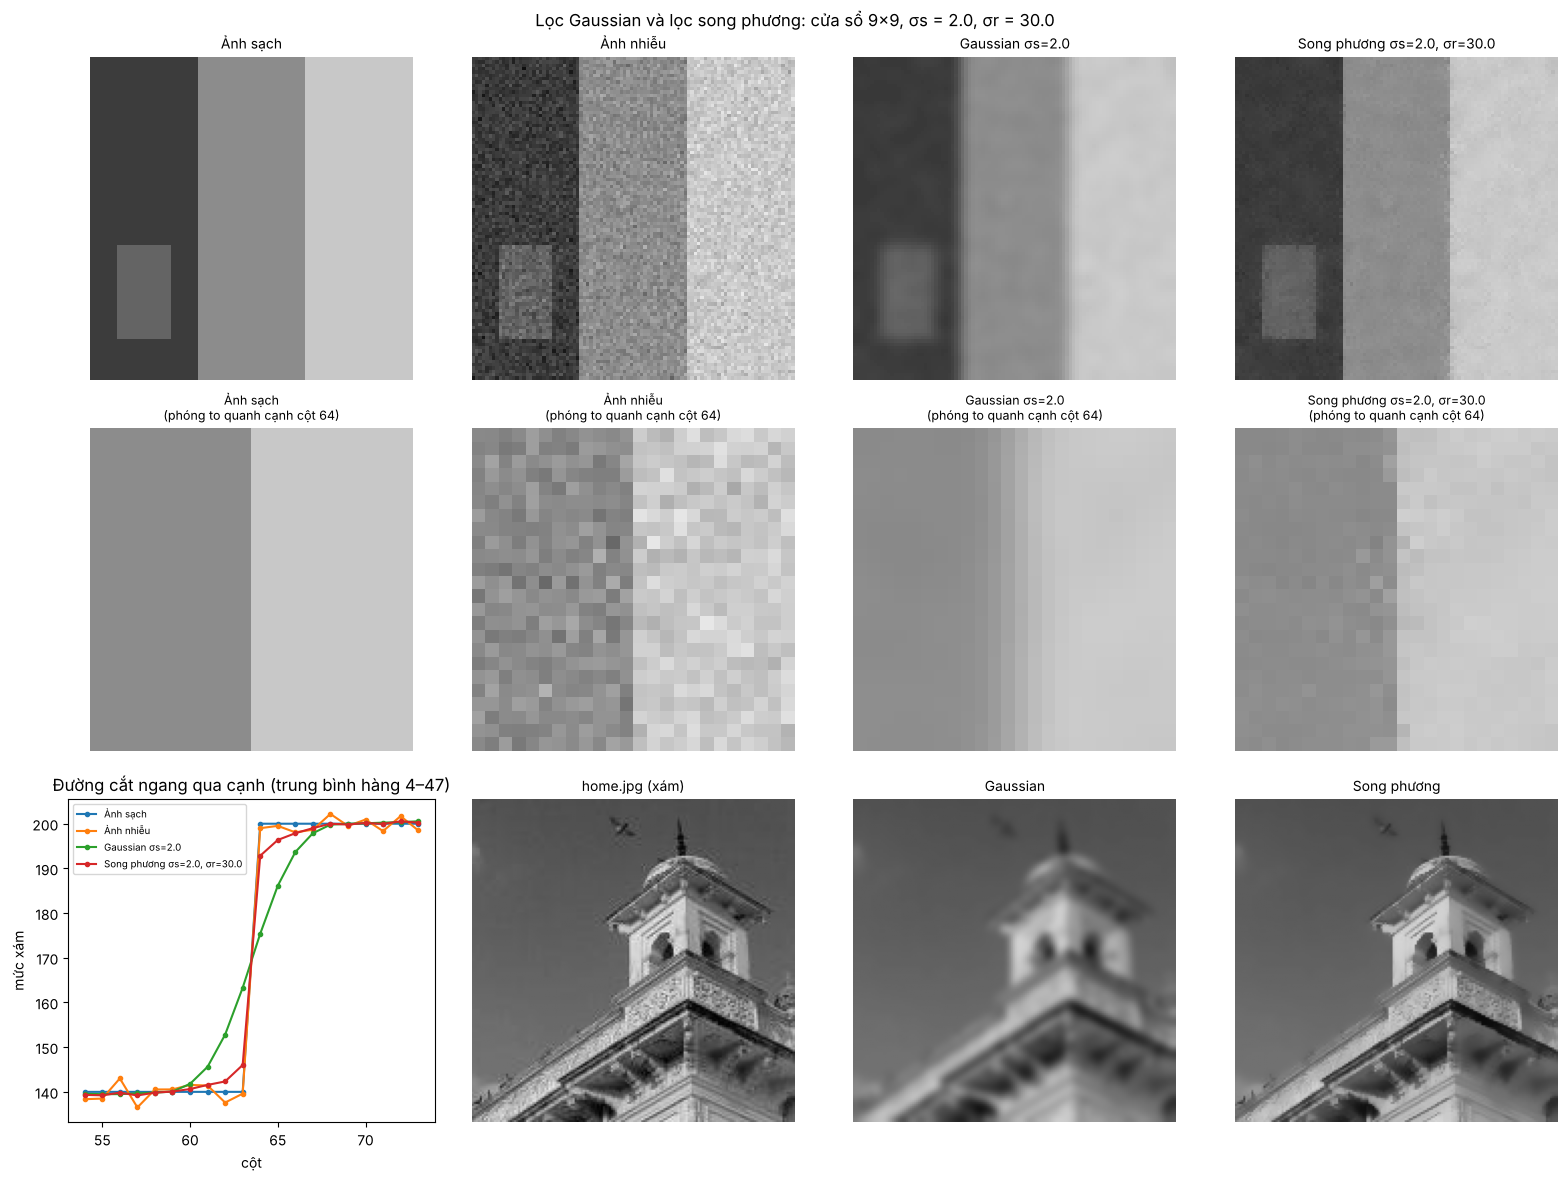

Đã lưu: images/song_phuong_so_sanh.png


In [17]:
# Ảnh thật: một vùng 160×160 của home.jpg, chuyển xám theo trọng số luminance (slide 34)
anh_mau = plt.imread(thu_muc.parent / "images" / "home.jpg")[..., :3].astype(np.float64)
anh_that = 0.299 * anh_mau[..., 0] + 0.587 * anh_mau[..., 1] + 0.114 * anh_mau[..., 2]
anh_that = anh_that[120:280, 180:340]
that_gauss = convolve2d(anh_that, gaussian_kernel(2 * R_LOC + 1, SIGMA_S), padding="reflect")
that_loc = {"home.jpg (xám)": anh_that, "Gaussian": that_gauss}
if co_ham:
    that_loc["Song phương"] = bilateral_filter(anh_that, R_LOC, SIGMA_S, SIGMA_R)
else:
    that_loc["Song phương (chưa có hàm)"] = None

hang_1 = {"Ảnh sạch": anh_sach, **ket_qua_loc}
if not co_ham:
    hang_1["Song phương (chưa có hàm)"] = None

fig, axes = plt.subplots(3, 4, figsize=(16, 12))


def ve_anh(ax, anh, ten, co_chu=None, **kw):
    if anh is None:   # chưa có hàm song phương: ghi chú thay vì vẽ ảnh
        ax.text(0.5, 0.5, "Hiệp chưa viết\nbilateral_filter", ha="center", va="center", transform=ax.transAxes)
    else:
        ax.imshow(anh, cmap="gray", vmin=0, vmax=255, **kw)
    ax.set_title(ten, fontsize=co_chu)


for ax, (ten, anh) in zip(axes[0], hang_1.items()):
    ve_anh(ax, anh, ten)
for ax, (ten, anh) in zip(axes[1], hang_1.items()):
    ve_anh(ax, None if anh is None else anh[20:44, 52:76], ten + "\n(phóng to quanh cạnh cột 64)",
           co_chu=9, interpolation="nearest")
ax = axes[2, 0]
for ten, anh in hang_1.items():
    if anh is not None:
        ax.plot(np.arange(54, 74), anh[4:48, 54:74].mean(axis=0), "o-", markersize=3, label=ten)
ax.set_title("Đường cắt ngang qua cạnh (trung bình hàng 4–47)")
ax.set_xlabel("cột"); ax.set_ylabel("mức xám"); ax.legend(fontsize=7)
for ax, (ten, anh) in zip(axes[2, 1:], that_loc.items()):
    ve_anh(ax, anh, ten)
for ax in axes.flat:
    if ax is not axes[2, 0]:
        ax.axis("off")
fig.suptitle(f"Lọc Gaussian và lọc song phương: cửa sổ {2 * R_LOC + 1}×{2 * R_LOC + 1}, σs = {SIGMA_S}, σr = {SIGMA_R}")
plt.tight_layout()
plt.savefig(thu_muc.parent / "images" / "song_phuong_so_sanh.png", dpi=110)
plt.show()
print("Đã lưu: images/song_phuong_so_sanh.png")


### Nhận xét
_Bản nháp do Claude viết từ số đo của lần chạy trong file này (ảnh thử cố định, seed = 0, nên chạy lại cho cùng số). Hiệp đối chiếu với bảng ở trên rồi viết lại bằng lời của mình._

- **Vùng phẳng:** độ lệch chuẩn vùng phẳng của ảnh nhiễu là 11.99, sau Gaussian là 1.73, sau song phương là 2.66 (OpenCV 2.80). Cả hai bộ lọc đều làm mịn vùng phẳng nhiều so với ảnh nhiễu. Song phương có thể còn hơi nhiễu hơn Gaussian một chút: hàng xóm nhiễu lệch xa (so với σr) bị giảm trọng số nên số điểm thực sự được lấy trung bình ít hơn. σr càng lớn thì vùng phẳng càng giống Gaussian, nhưng cạnh cũng nhòe dần.
- **Cạnh:** độ rộng cạnh 10–90% của ảnh sạch là 0.80 px, Gaussian là 5.11 px, song phương là 1.48 px (OpenCV 1.33 px). Gaussian lấy trung bình cả hai phía của cạnh nên cạnh bị nhòe; song phương gần như bỏ qua hàng xóm ở phía bên kia vì độ sáng khác xa (nhân giá trị ≈ 0).
- **Khác Gaussian chỗ nào:** trọng số = nhân không gian × nhân giá trị (CV40 mục 3.2). Gaussian chỉ có nhân không gian, giống nhau ở mọi chỗ; song phương đổi trọng số theo từng điểm ảnh, nên là toán tử điểm có tham số sinh bởi toán tử lân cận. Khi σr rất lớn, song phương trùng Gaussian (ô kiểm tra ở trên).
- **Liên hệ Canny (CV23 slide 27):** Canny làm mờ Gaussian trước khi tính gradient nên cạnh bị nhòe; thay bằng song phương giữ cạnh sắc trong khi vẫn làm mịn vùng phẳng.
